Realizado por:
Andrea Bonilla
July Aparicio
Ioshua Castillejos

# Clasificación de Sentimientos de Reseñas de Películas en IMDb con Redes Neuronales Recurrentes
## A - Objetivo

Desarrollar un método basado en redes neuronales recurrentes que permita clasificar con precisión las reseñas de películas en IMDb en una de las dos
categorías: positiva o negativa

## B - Conjunto de datos

Los datos corresponden a un dataset de reseñas de películas en IMDb,
disponibles en el siguiente enlace. El dataset contiene miles de reseñas
etiquetadas con su correspondiente rating y etiqueta de sentimiento (positivo o
negativo)

## C - Actividades por realizar
1. Preprocesamiento de las reseñas: Construir un pipeline que permita limpiar y
tokenizar las reseñas de texto, convirtiéndolas en secuencias numéricas
utilizando embeddings
2. Desarrollo de la arquitectura de red neuronal recurrente: Implementar una
RNN (por ejemplo, LSTM o GRU) para la clasificación de las reseñas en dos
categorías. La arquitectura de la red es de libre elección, pero se sugiere incluir
capas de embedding, capas recurrentes y una capa densa de salida con
activación sigmoide. Justificar la elección de cada capa del modelo.
3. Entrenamiento y evaluación del modelo: Dividir el dataset en conjuntos de
entrenamiento, validación y prueba. Entrenar el modelo utilizando el conjunto de
entrenamiento y evaluar su rendimiento con el conjunto de prueba, reportando
métricas de precisión, recall y F1-score.

### 1. Librerías

In [1]:
# Librerías requeridas
# PyTorch para construir y entrenar las redes
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
from sklearn.model_selection import train_test_split


import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader, random_split

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.preprocessing import StandardScaler

from time import time
from gensim.models import Word2Vec
from nltk.stem import PorterStemmer
stemmer = PorterStemmer()

import copy

# Para descargar los recursos desde la red con proxy (error de certificado SSL)
try:
    import truststore
    truststore.inject_into_ssl()
except ImportError:
    pass

import nltk
from nltk.corpus import stopwords
from wordcloud import WordCloud

# Se descargan los recursos de NLTK si no están instalados
for recurso, ruta in [('punkt', 'tokenizers/punkt'),
                      ('punkt_tab', 'tokenizers/punkt_tab'),
                      ('stopwords', 'corpora/stopwords')]:
    try:
        nltk.data.find(ruta)
    except LookupError:
        nltk.download(recurso, quiet=True)

# Semillas
torch.manual_seed(3)
np.random.seed(3)

# Se usa GPU si está disponible
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Usando dispositivo: {device}')

# Librerías para el modelo con GloVe
import os
from collections import Counter
from gensim.models import KeyedVectors
import gensim.downloader as api

Usando dispositivo: cuda


### 2. Importar los datos

In [2]:
GHI = pd.read_csv('movie.csv')
GHI.info()

<class 'pandas.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   text    40000 non-null  str  
 1   label   40000 non-null  int64
dtypes: int64(1), str(1)
memory usage: 50.6 MB


### 3. Exploración de datos

In [3]:
GHI.head()

,text,label
0,I grew up (b. 1965) watching and loving the Th...,0
1,"When I put this movie in my DVD player, and sa...",0
2,Why do people who do not know what a particula...,0
3,Even though I have great interest in Biblical ...,0
4,Im a die hard Dads Army fan and nothing will e...,1


In [4]:
GHI['label'].value_counts()

label
0    20019
1    19981
Name: count, dtype: int64

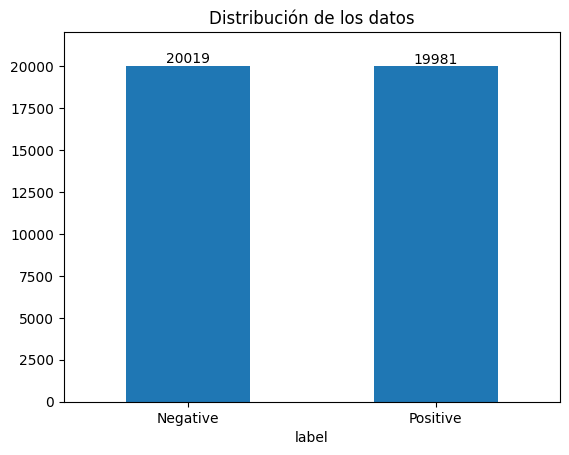

In [5]:
ax = GHI.groupby('label').count().plot(kind='bar', title='Distribución de los datos',
                                       legend=False)
ax.set_xticklabels(['Negative', 'Positive'], rotation=0)

for container in ax.containers:
    ax.bar_label(container)

ax.margins(y=0.1)  # espacio para las etiquetas


In [6]:
longitudes = GHI['text'].str.split().str.len()
print(f"Textos muy cortos (<5 palabras): {(longitudes < 5).sum()}")
print(f"Textos muy largos (>1000 palabras): {(longitudes > 1000).sum()}")
print(f"Filas con registros nulos: {GHI['text'].isnull().sum()}")
print(f"Filas invalidas: {GHI['text'].isna().sum()}")
print(f"Filas duplicadas: {GHI['text'].duplicated().sum()}")

Textos muy cortos (<5 palabras): 1
Textos muy largos (>1000 palabras): 60
Filas con registros nulos: 0
Filas invalidas: 0
Filas duplicadas: 277


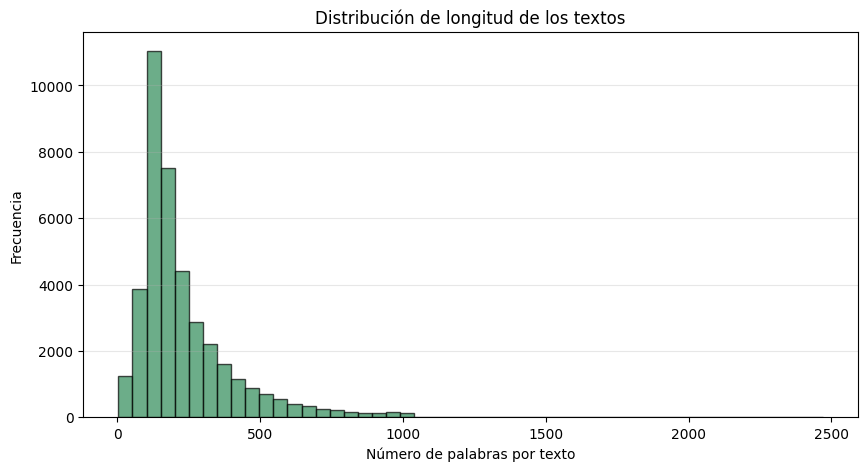

count    40000.000000
mean       231.339250
std        171.194123
min          4.000000
25%        126.000000
50%        173.000000
75%        282.000000
max       2470.000000
Name: text, dtype: float64


In [7]:
longitudes = GHI['text'].str.split().str.len()

plt.figure(figsize=(10,5))
plt.hist(longitudes, bins=50, color='seagreen', edgecolor='black', alpha=0.7)
plt.xlabel('Número de palabras por texto')
plt.ylabel('Frecuencia')
plt.title('Distribución de longitud de los textos')
plt.grid(axis='y', alpha=0.3)
plt.show()

print(longitudes.describe())

Hallazgos de la exploración de datos.

Las dos clases están casi balanceadas (20.019 reseñas negativas y 19.981 positivas), por lo que no fue necesario balancear los datos. No hay valores nulos, pero sí 277 reseñas repetidas, que se eliminan antes de dividir los datos. En promedio las reseñas tienen 231 palabras y la mediana es de 173; la más corta tiene 4 palabras y la más larga 2.470, por eso el histograma tiene una cola larga hacia la derecha. Solo una reseña tiene menos de 5 palabras y 60 tienen más de 1.000.

### 4. Separación de datos

Primero se eliminan las reseñas duplicadas, para que una misma reseña no quede a la vez en entrenamiento y en prueba; quedan 39.723 registros. Después los datos se dividen en 70 % entrenamiento (27.806), 15 % validación (5.958) y 15 % prueba (5.959), estratificando por la etiqueta para mantener la proporción de clases. La división usa la semilla 3.

In [8]:
# Se quitan los duplicados antes de dividir
GHI = GHI.drop_duplicates(subset='text').reset_index(drop=True)
print(f"Registros tras eliminar duplicados: {len(GHI)}")

SEED = 3

# 70% train, 15% validación, 15% prueba
train_GHI, resto = train_test_split(GHI, test_size=0.30, stratify=GHI["label"], random_state=SEED)
val_GHI, test_GHI = train_test_split(resto, test_size=0.50, stratify=resto["label"], random_state=SEED)
print(f"Datos entrenamiento: {len(train_GHI)}\nDatos validacion: {len(val_GHI)} \nDatos prueba: {len(test_GHI)}")

Registros tras eliminar duplicados: 39723
Datos entrenamiento: 27806
Datos validacion: 5958 
Datos prueba: 5959


### 5. Función de limpieza de textos

La función `limpiar_texto` convierte las entidades HTML (`&amp;`), quita las etiquetas HTML como `<br />` y las URLs, y pasa todo a minúsculas. Las negaciones contraídas se separan (*won't* → *will not*, *can't* → *can not*, *didn't* → *did not*), las demás contracciones (*'s*, *'re*, *'ll*...) se eliminan y se dejan solo letras.

Después se quitan las stopwords de NLTK y las palabras de una sola letra, pero se conservan *no*, *nor*, *not*, *but*, *very*, *too*, *against* y *only*, porque cambian el sentido de la reseña. Por último cada palabra se reduce a su raíz con el stemmer de Porter (*movies* → *movi*). La limpieza se aplica a los tres conjuntos y el resultado queda en la columna `palabras_limpias`.

In [9]:
import re
import html

# Se conservan las negaciones y palabras que cambian el sentido
conservar = {'no', 'nor', 'not', 'but', 'very', 'too', 'against', 'only'}
stop_words = set(stopwords.words('english')) - conservar

def limpiar_texto(texto, quitar_stopwords=True):
    texto = html.unescape(texto)
    texto = re.sub(r'<[^>]+>', ' ', texto)  # html
    texto = re.sub(r'http\S+|www\.\S+', ' ', texto)  # urls
    texto = texto.lower().replace('\u2019', "'")  # minúsculas
    texto = re.sub(r"\bwon't\b", 'will not', texto)  # negaciones
    texto = re.sub(r"\bcan't\b", 'can not', texto)
    texto = re.sub(r"n't\b", ' not', texto)
    texto = re.sub(r"'(s|re|ve|d|ll|m)\b", ' ', texto)  # contracciones
    texto = re.sub(r'[^a-z\s]', ' ', texto)  # solo letras
    palabras_limpias = texto.split()
    if quitar_stopwords:
        palabras_limpias = [t for t in palabras_limpias if t not in stop_words and len(t) > 1]
        palabras_limpias = [stemmer.stem(t) for t in palabras_limpias]
    # Retorna la lista de palabras limpias
    return palabras_limpias

print(limpiar_texto("I didn't like it.<br /><br />It WASN'T good &amp; I can't recommend it!!"))

# Limpieza de train, validación y prueba
for conjunto in (train_GHI, val_GHI, test_GHI):
    conjunto['palabras_limpias'] = conjunto['text'].apply(limpiar_texto)

['not', 'like', 'not', 'good', 'not', 'recommend']


### 6. Vocabulario y secuencias

El vocabulario se construye solo con los datos de entrenamiento, para no filtrar información de validación y prueba. El 0 es para el padding, el 1 para las palabras desconocidas y el resto para las 19.998 palabras más frecuentes (20.000 índices en total). Cada reseña se convierte en una secuencia de 400 índices: si es corta se rellena con ceros al inicio y si es larga se conserva el final. Los lotes son de 128 para entrenamiento y de 256 para validación y prueba.

In [10]:
MAX_VOCAB = 20000
MAX_LEN = 400
EMB_DIM = 300

# 0 = padding, 1 = desconocida
contador = Counter(t for toks in train_GHI["palabras_limpias"] for t in toks)
palabras = [p for p, _ in contador.most_common(MAX_VOCAB - 2)]
word2idx = {p: i + 2 for i, p in enumerate(palabras)}

def codificar(tokens):
    ids = [word2idx.get(t, 1) for t in tokens][-MAX_LEN:]   # se deja el final de la reseña
    return [0] * (MAX_LEN - len(ids)) + ids

def a_tensores(df):
    X = torch.tensor([codificar(t) for t in df["palabras_limpias"]], dtype=torch.long)
    y = torch.tensor(df["label"].values, dtype=torch.float32)
    return X, y

X_train, y_train = a_tensores(train_GHI)
X_val, y_val = a_tensores(val_GHI)
X_test, y_test = a_tensores(test_GHI)

train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=128, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val, y_val), batch_size=256)
test_loader = DataLoader(TensorDataset(X_test, y_test), batch_size=256)
print(X_train.shape, X_val.shape, X_test.shape)

torch.Size([27806, 400]) torch.Size([5958, 400]) torch.Size([5959, 400])


### 7. Embeddings GloVe

Se usan los vectores preentrenados de GloVe de 300 dimensiones. Si `glove.6B.300d.txt` está en la carpeta se lee de ahí; si no, se descarga con gensim (`glove-wiki-gigaword-300`). Con esos vectores se arma la matriz de embeddings en el orden del vocabulario. Las palabras que no están en GloVe quedan con un vector aleatorio (con la misma desviación estándar de los vectores de GloVe) y el padding en ceros. Hay que tener en cuenta que, como las palabras pasaron por stemming, muchas no se encuentran en GloVe.

In [11]:
if os.path.exists("glove.6B.300d.txt"):
    glove = KeyedVectors.load_word2vec_format("glove.6B.300d.txt", binary=False, no_header=True)
else:
    glove = api.load("glove-wiki-gigaword-300")

print(glove.most_similar("great", topn=5))
print(glove.most_similar("terrible", topn=5))

encontradas = [p for p in word2idx if p in glove]
desv = np.std([glove[p] for p in encontradas])
rng = np.random.default_rng(SEED)

emb_matrix = rng.normal(scale=desv, size=(MAX_VOCAB, EMB_DIM)).astype(np.float32)
emb_matrix[0] = 0
for palabra in encontradas:
    emb_matrix[word2idx[palabra]] = glove[palabra]
print(f"Palabras con vector de GloVe: {len(encontradas):,} de {len(word2idx):,}")

del glove

[('greatest', 0.6583032608032227), ('good', 0.6410046815872192), ('tremendous', 0.6299972534179688), ('well', 0.5856286883354187), ('especially', 0.5592252612113953)]
[('horrible', 0.8621524572372437), ('awful', 0.7882837653160095), ('dreadful', 0.7239290475845337), ('horrendous', 0.6983873844146729), ('horrific', 0.6624177098274231)]
Palabras con vector de GloVe: 14,144 de 19,998


### 8. Modelo

La primera capa es el embedding, inicializado con la matriz de GloVe. Así el modelo no empieza desde cero y ya trae relaciones entre palabras. Se deja entrenable (`freeze=False`) para que se ajuste a las reseñas. Después se agrega un dropout de 0.3 para reducir el sobreajuste.

Para la parte recurrente se usa una LSTM bidireccional de 128 unidades. Se escogió LSTM y no una RNN simple porque las reseñas son largas (hasta 400 tokens) y la RNN simple pierde la información del principio por el desvanecimiento del gradiente. Es bidireccional porque el sentido de una palabra a veces depende de lo que viene después, por ejemplo en "not bad at all". Cada palabra queda con un vector de 256 (128 por dirección).

Después de la LSTM va una capa de atención. Una capa lineal le da un puntaje a cada palabra, se aplica softmax y con esos pesos se hace un promedio de las salidas de la LSTM. De esta forma el modelo no depende solo del último estado y puede darle más importancia a palabras como *awful* o *masterpiece*. El padding se enmascara para que no cuente.

Al final van un dropout de 0.4, una capa densa de 64 neuronas con ReLU y una neurona de salida. Esa neurona da un logit y no una probabilidad, porque se usa `BCEWithLogitsLoss`, que ya incluye la sigmoide y es más estable numéricamente. Al predecir se aplica `torch.sigmoid` con un umbral de 0.5.

El entrenamiento se hace con Adam (lr = 0.001, weight decay = 1e-5) y la norma del gradiente se recorta a 1.0 para que los gradientes de la LSTM no se disparen.

In [12]:
class ModeloRNN(nn.Module):
    def __init__(self, emb_matrix, hidden=128):
        super().__init__()
        self.emb = nn.Embedding.from_pretrained(torch.tensor(emb_matrix), freeze=False, padding_idx=0)
        self.drop_emb = nn.Dropout(0.3)
        self.lstm = nn.LSTM(emb_matrix.shape[1], hidden, batch_first=True, bidirectional=True)
        self.atencion = nn.Linear(hidden * 2, 1)
        self.drop = nn.Dropout(0.4)
        self.fc = nn.Linear(hidden * 2, 64)
        self.relu = nn.ReLU()
        self.out = nn.Linear(64, 1)

    def forward(self, x):
        mascara = (x != 0)
        salida, _ = self.lstm(self.drop_emb(self.emb(x)))

        # atención (sin contar el padding)
        puntajes = self.atencion(salida).squeeze(-1)
        puntajes = puntajes.masked_fill(~mascara, -1e9)
        pesos = torch.softmax(puntajes, dim=1)
        h = (salida * pesos.unsqueeze(-1)).sum(dim=1)

        h = self.relu(self.fc(self.drop(h)))
        return self.out(h).squeeze(1)

modelo = ModeloRNN(emb_matrix).to(device)
criterio = nn.BCEWithLogitsLoss()
optimizador = optim.Adam(modelo.parameters(), lr=1e-3, weight_decay=1e-5)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizador, mode="min", factor=0.5, patience=1)

print(modelo)
print(f"Parámetros entrenables: {sum(p.numel() for p in modelo.parameters() if p.requires_grad):,}")

ModeloRNN(
  (emb): Embedding(20000, 300, padding_idx=0)
  (drop_emb): Dropout(p=0.3, inplace=False)
  (lstm): LSTM(300, 128, batch_first=True, bidirectional=True)
  (atencion): Linear(in_features=256, out_features=1, bias=True)
  (drop): Dropout(p=0.4, inplace=False)
  (fc): Linear(in_features=256, out_features=64, bias=True)
  (relu): ReLU()
  (out): Linear(in_features=64, out_features=1, bias=True)
)
Parámetros entrenables: 6,457,090


### 9. Entrenamiento con validación

En cada época el modelo se entrena con train y se evalúa con validación. Se guarda el modelo con mejor accuracy en validación y se usa early stopping con paciencia de 5 épocas (máximo 50). Si la pérdida de validación no baja, `ReduceLROnPlateau` reduce la tasa de aprendizaje a la mitad. Al terminar se cargan los pesos del mejor modelo y se grafican las curvas de pérdida y accuracy.

In [13]:
def ejecutar_epoca(loader, entrenar):
    modelo.train() if entrenar else modelo.eval()
    perdida_total, aciertos, n = 0.0, 0, 0
    with torch.set_grad_enabled(entrenar):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            salida = modelo(xb)
            perdida = criterio(salida, yb)
            if entrenar:
                optimizador.zero_grad()
                perdida.backward()
                nn.utils.clip_grad_norm_(modelo.parameters(), 1.0)
                optimizador.step()
            perdida_total += perdida.item() * len(yb)
            aciertos += ((torch.sigmoid(salida) >= 0.5).float() == yb).sum().item()
            n += len(yb)
    return perdida_total / n, aciertos / n

EPOCAS = 50
PACIENCIA = 5

historial = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
mejor_val_acc = 0.0
mejor_estado = None
sin_mejora = 0
inicio = time()

for epoca in range(1, EPOCAS + 1):
    tr_loss, tr_acc = ejecutar_epoca(train_loader, entrenar=True)
    va_loss, va_acc = ejecutar_epoca(val_loader, entrenar=False)
    scheduler.step(va_loss)

    historial["train_loss"].append(tr_loss)
    historial["val_loss"].append(va_loss)
    historial["train_acc"].append(tr_acc)
    historial["val_acc"].append(va_acc)
    print(f"Época {epoca:2d} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
          f"val loss {va_loss:.4f} acc {va_acc:.4f} | lr {optimizador.param_groups[0]['lr']:.1e}")

    # early stopping
    if va_acc > mejor_val_acc:
        mejor_val_acc = va_acc
        mejor_estado = copy.deepcopy(modelo.state_dict())
        sin_mejora = 0
    else:
        sin_mejora += 1
        if sin_mejora >= PACIENCIA:
            print(f"Early stopping en la época {epoca}")
            break

modelo.load_state_dict(mejor_estado)
print(f"Tiempo de entrenamiento: {time() - inicio:.1f} s | mejor val acc: {mejor_val_acc:.4f}")

Época  1 | train loss 0.4128 acc 0.8011 | val loss 0.3011 acc 0.8731 | lr 1.0e-03
Época  2 | train loss 0.2449 acc 0.9038 | val loss 0.2712 acc 0.8857 | lr 1.0e-03
Época  3 | train loss 0.1858 acc 0.9297 | val loss 0.2728 acc 0.8922 | lr 1.0e-03
Época  4 | train loss 0.1437 acc 0.9490 | val loss 0.3137 acc 0.8889 | lr 5.0e-04
Época  5 | train loss 0.0917 acc 0.9698 | val loss 0.3520 acc 0.8904 | lr 5.0e-04
Época  6 | train loss 0.0755 acc 0.9751 | val loss 0.4136 acc 0.8865 | lr 2.5e-04
Época  7 | train loss 0.0570 acc 0.9819 | val loss 0.4335 acc 0.8872 | lr 2.5e-04
Época  8 | train loss 0.0485 acc 0.9848 | val loss 0.4524 acc 0.8862 | lr 1.3e-04
Early stopping en la época 8
Tiempo de entrenamiento: 310.5 s | mejor val acc: 0.8922


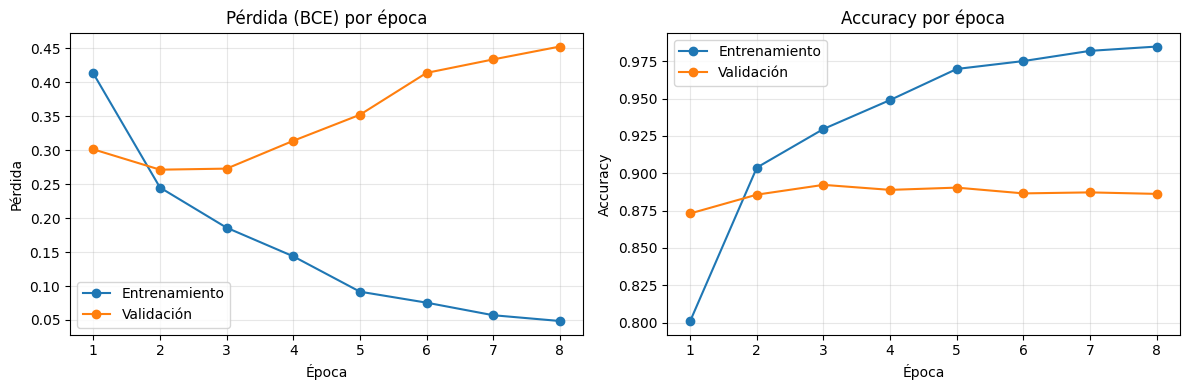

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
epocas_x = range(1, len(historial["train_loss"]) + 1)

axes[0].plot(epocas_x, historial["train_loss"], marker="o", label="Entrenamiento")
axes[0].plot(epocas_x, historial["val_loss"], marker="o", label="Validación")
axes[0].set_title("Pérdida (BCE) por época")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Pérdida")

axes[1].plot(epocas_x, historial["train_acc"], marker="o", label="Entrenamiento")
axes[1].plot(epocas_x, historial["val_acc"], marker="o", label="Validación")
axes[1].set_title("Accuracy por época")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Accuracy")

for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

### 10. Evaluación en el conjunto de prueba

El mejor modelo se evalúa una sola vez con el conjunto de prueba (15 %), que no se usó ni para entrenar ni para escoger el modelo. Se reportan accuracy, precisión, recall, F1-score y la matriz de confusión.

Accuracy : 0.8938
Precisión: 0.8838
Recall   : 0.9072
F1-score : 0.8954

              precision    recall  f1-score   support

    Negativa     0.9043    0.8803    0.8921      2973
    Positiva     0.8838    0.9072    0.8954      2986

    accuracy                         0.8938      5959
   macro avg     0.8941    0.8937    0.8937      5959
weighted avg     0.8940    0.8938    0.8938      5959



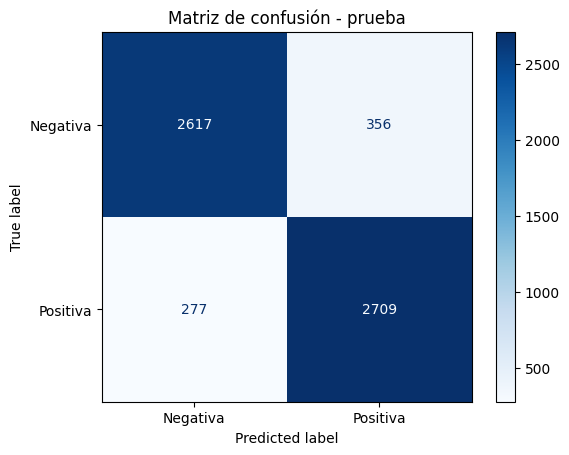

In [15]:
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             accuracy_score, precision_score, recall_score, f1_score)

modelo.eval()
probs, reales = [], []
with torch.no_grad():
    for xb, yb in test_loader:
        probs.append(torch.sigmoid(modelo(xb.to(device))).cpu())
        reales.append(yb)
probs = torch.cat(probs).numpy()
y_real = torch.cat(reales).numpy().astype(int)
y_pred = (probs >= 0.5).astype(int)

print(f"Accuracy : {accuracy_score(y_real, y_pred):.4f}")
print(f"Precisión: {precision_score(y_real, y_pred):.4f}")
print(f"Recall   : {recall_score(y_real, y_pred):.4f}")
print(f"F1-score : {f1_score(y_real, y_pred):.4f}")
print()
print(classification_report(y_real, y_pred, target_names=["Negativa", "Positiva"], digits=4))

ConfusionMatrixDisplay(confusion_matrix(y_real, y_pred),
                       display_labels=["Negativa", "Positiva"]).plot(cmap="Blues", values_format="d")
plt.title("Matriz de confusión - prueba")
plt.show()

### 11. Pérdida en test, AUC y accuracy por longitud

Se calcula la pérdida en prueba para compararla con la de validación, y el AUC de la curva ROC. También se revisa el accuracy según la cantidad de tokens de cada reseña, para ver si el modelo falla más en las reseñas cortas o en las de más de 400 tokens, que quedan recortadas.

Pérdida test: 0.2632 | mejor pérdida validación: 0.2712
AUC test: 0.9598
         reseñas  accuracy
rango                     
0-50         652    0.9034
51-100      2571    0.8868
101-200     1817    0.8899
201-400      757    0.9102
>400         162    0.9321


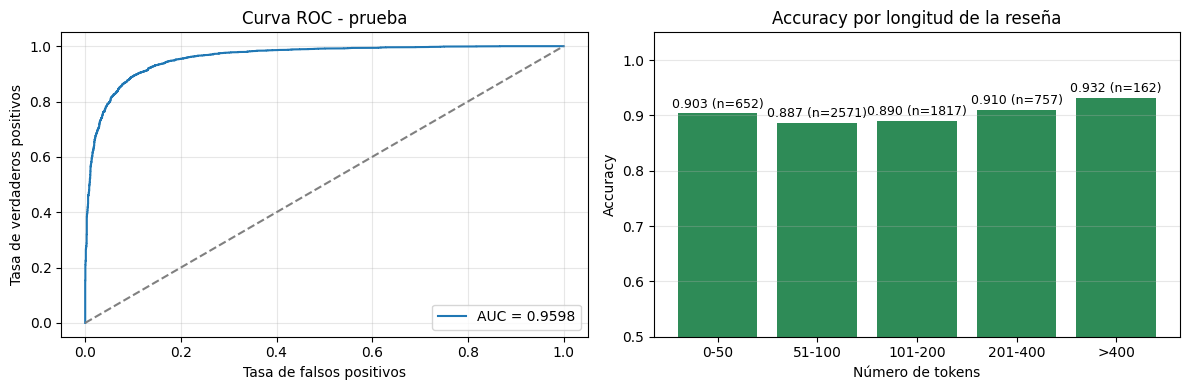

In [16]:
from sklearn.metrics import roc_auc_score, roc_curve

modelo.eval()
logits = []
with torch.no_grad():
    for xb, _ in test_loader:
        logits.append(modelo(xb.to(device)).cpu())
logits = torch.cat(logits)

test_loss = criterio(logits, torch.tensor(y_real, dtype=torch.float32)).item()
auc = roc_auc_score(y_real, probs)
print(f"Pérdida test: {test_loss:.4f} | mejor pérdida validación: {min(historial['val_loss']):.4f}")
print(f"AUC test: {auc:.4f}")

# test_loader no tiene shuffle, el orden es el mismo de test_GHI
resultados = pd.DataFrame({
    "n_tokens": test_GHI["palabras_limpias"].str.len().values,
    "real": y_real,
    "pred": y_pred,
    "prob": probs,
})
resultados["acierto"] = (resultados["real"] == resultados["pred"]).astype(int)

cortes = [0, 50, 100, 200, 400, np.inf]
etiquetas = ["0-50", "51-100", "101-200", "201-400", ">400"]
resultados["rango"] = pd.cut(resultados["n_tokens"], bins=cortes, labels=etiquetas)
por_longitud = resultados.groupby("rango", observed=False).agg(reseñas=("acierto", "size"),
                                                               accuracy=("acierto", "mean"))
print(por_longitud.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

fpr, tpr, _ = roc_curve(y_real, probs)
axes[0].plot(fpr, tpr, label=f"AUC = {auc:.4f}")
axes[0].plot([0, 1], [0, 1], "--", color="gray")
axes[0].set_title("Curva ROC - prueba")
axes[0].set_xlabel("Tasa de falsos positivos")
axes[0].set_ylabel("Tasa de verdaderos positivos")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].bar(etiquetas, por_longitud["accuracy"], color="seagreen")
for i, (acc, n) in enumerate(zip(por_longitud["accuracy"], por_longitud["reseñas"])):
    axes[1].text(i, acc + 0.01, f"{acc:.3f} (n={n})", ha="center", fontsize=9)
axes[1].set_ylim(0.5, 1.05)
axes[1].set_title("Accuracy por longitud de la reseña")
axes[1].set_xlabel("Número de tokens")
axes[1].set_ylabel("Accuracy")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### 12. Ejemplos de errores

Para entender en qué se equivoca el modelo, se revisan los errores en los que estaba más seguro: las reseñas negativas con mayor probabilidad de ser positivas (falsos positivos) y las positivas con menor probabilidad (falsos negativos). Se muestran 5 de cada tipo.

In [17]:
resultados["texto"] = test_GHI["text"].str.replace("<br />", " ").values

fp = resultados[(resultados["real"] == 0) & (resultados["pred"] == 1)]
fn = resultados[(resultados["real"] == 1) & (resultados["pred"] == 0)]
print("Falsos positivos:", len(fp))
print("Falsos negativos:", len(fn))

print("----- Falsos positivos (negativas que el modelo dio como positivas) -----")
for _, fila in fp.sort_values("prob", ascending=False).head(5).iterrows():
    print(f"Probabilidad: {fila['prob']:.3f} | Tokens: {fila['n_tokens']}")
    print(fila["texto"][:500])

print("----- Falsos negativos (positivas que el modelo dio como negativas) -----")
for _, fila in fn.sort_values("prob").head(5).iterrows():
    print(f"Probabilidad: {fila['prob']:.3f} | Tokens: {fila['n_tokens']}")
    print(fila["texto"][:500])

Falsos positivos: 356
Falsos negativos: 277
----- Falsos positivos (negativas que el modelo dio como positivas) -----
Probabilidad: 0.996 | Tokens: 73
This sleek, sexy movie is a must-see. Only upon multiple viewings can one truly understand the uniqueness of this film. Personally I enjoy the narrator for his intelligent, no subject left untouched, style of narration. The introduction grips you right away, and holds you at the edge of your seat throughout the film. He provides wonderful insight into the world of the trainables and allows the audience to really 'connect' with internal horror this film exhibits. The script itself holds the movie
Probabilidad: 0.993 | Tokens: 130
I have watched this movie a few times and never really thought it was that funny, but it's still fun to watch and good for a few laughs.  Its about women that work at a company and their boss is a jerk and they end up giving him a taste of his own medicine, and try to get the respect they deserve.  The acting is 

## Modelo con embeddings Word2Vec (comparación con GloVe 300d)

Para comparar, también se entrena un modelo con embeddings Word2Vec de 100 dimensiones entrenados con las reseñas del conjunto de entrenamiento. Se usan los mismos conjuntos de entrenamiento, validación y prueba y el mismo vocabulario. Las variables de esta parte llevan el sufijo `_w2v` para no perder los resultados del modelo con GloVe.

### 13. Embeddings Word2Vec

Word2Vec se entrena solo con las reseñas de entrenamiento, con vectores de 100 dimensiones, ventana de 5 y `min_count=1`.

In [18]:
from gensim.models import Word2Vec

EMB_DIM_W2V = 100

w2v = Word2Vec(
    sentences=train_GHI["palabras_limpias"].tolist(),
    vector_size=EMB_DIM_W2V,
    window=5,
    min_count=1,
    workers=4,
    seed=SEED,
)

print(f"Palabras en el modelo Word2Vec: {len(w2v.wv):,}")
print("Similares a 'great':", w2v.wv.most_similar('great', topn=5))

Palabras en el modelo Word2Vec: 53,683
Similares a 'great': [('excel', 0.7629820704460144), ('fine', 0.7336481809616089), ('fantast', 0.7249836325645447), ('terrif', 0.6884322762489319), ('good', 0.6741465926170349)]


### 14. Matriz con embeddings y tensores

Se usa el mismo vocabulario de 20.000 índices. En este modelo las secuencias son de 300 índices y, a diferencia del modelo con GloVe, se conserva el inicio de la reseña. El padding va al inicio. Cada fila de la matriz toma el vector de Word2Vec de su palabra y el padding queda en ceros; como Word2Vec se entrenó con `min_count=1`, todas las palabras del vocabulario tienen vector. Los lotes son de 128 para entrenamiento y de 256 para validación y prueba.

In [19]:
MAX_LEN_W2V = 300
VOCAB_SIZE_W2V = len(word2idx) + 2

def codificar_w2v(tokens):
    ids = [word2idx.get(t, 1) for t in tokens][:MAX_LEN_W2V]
    # padding al inicio
    return [0] * (MAX_LEN_W2V - len(ids)) + ids

# Matriz de embeddings con los vectores de Word2Vec
matriz_emb_w2v = np.random.normal(0, 0.1, (VOCAB_SIZE_W2V, EMB_DIM_W2V)).astype("float32")
matriz_emb_w2v[0] = 0.0  # padding
encontradas_w2v = 0
for palabra, idx in word2idx.items():
    if palabra in w2v.wv:
        matriz_emb_w2v[idx] = w2v.wv[palabra]
        encontradas_w2v += 1
print(f"Palabras con vector Word2Vec: {encontradas_w2v:,} / {len(word2idx):,}")

def a_tensores_w2v(frame):
    X = torch.tensor([codificar_w2v(t) for t in frame["palabras_limpias"]], dtype=torch.long)
    y = torch.tensor(frame["label"].values, dtype=torch.float32)
    return X, y

X_train_w2v, y_train_w2v = a_tensores_w2v(train_GHI)
X_val_w2v, y_val_w2v = a_tensores_w2v(val_GHI)
X_test_w2v, y_test_w2v = a_tensores_w2v(test_GHI)

train_loader_w2v = DataLoader(TensorDataset(X_train_w2v, y_train_w2v), batch_size=128, shuffle=True)
val_loader_w2v = DataLoader(TensorDataset(X_val_w2v, y_val_w2v), batch_size=256)
test_loader_w2v = DataLoader(TensorDataset(X_test_w2v, y_test_w2v), batch_size=256)
print(X_train_w2v.shape, X_val_w2v.shape, X_test_w2v.shape)

Palabras con vector Word2Vec: 19,998 / 19,998
torch.Size([27806, 300]) torch.Size([5958, 300]) torch.Size([5959, 300])


### 15. Modelo Word2Vec

El embedding es de 100 dimensiones, se inicializa con Word2Vec y se deja entrenable, con un dropout de 0.3. Después van dos capas LSTM de 128 unidades en una sola dirección, con dropout de 0.3 entre ellas; se toma el último estado oculto de la segunda capa, se le aplica dropout y pasa a una neurona con sigmoide que da la probabilidad de que la reseña sea positiva. Se entrena con `BCELoss`, Adam (lr = 0.001, weight decay = 1e-5) y `ReduceLROnPlateau`, y la norma del gradiente se recorta a 1.0.

In [20]:
class SentimentLSTM(nn.Module):
    def __init__(self, vocab_size, emb_dim=100, hidden_dim=128, num_layers=2, dropout=0.3):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=0)
        self.emb_dropout = nn.Dropout(dropout)
        self.lstm = nn.LSTM(emb_dim, hidden_dim, num_layers=num_layers,
                            batch_first=True, dropout=dropout if num_layers > 1 else 0)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        emb = self.emb_dropout(self.embedding(x))
        _, (h_n, _) = self.lstm(emb)
        h = self.dropout(h_n[-1])  # último estado oculto
        return self.sigmoid(self.fc(h)).squeeze(1)

torch.manual_seed(SEED)
modelo_w2v = SentimentLSTM(VOCAB_SIZE_W2V, EMB_DIM_W2V).to(device)
modelo_w2v.embedding.weight.data.copy_(torch.tensor(matriz_emb_w2v))
modelo_w2v.embedding.weight.requires_grad = True
criterio_w2v = nn.BCELoss()
optimizador_w2v = optim.Adam(modelo_w2v.parameters(), lr=1e-3, weight_decay=1e-5)  # regularización L2
# Se reduce el lr a la mitad si la pérdida de validación no baja
scheduler_w2v = optim.lr_scheduler.ReduceLROnPlateau(optimizador_w2v, mode="min", factor=0.5, patience=1)

print(modelo_w2v)
print(f"Parámetros entrenables: {sum(p.numel() for p in modelo_w2v.parameters() if p.requires_grad):,}")

SentimentLSTM(
  (embedding): Embedding(20000, 100, padding_idx=0)
  (emb_dropout): Dropout(p=0.3, inplace=False)
  (lstm): LSTM(100, 128, num_layers=2, batch_first=True, dropout=0.3)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=128, out_features=1, bias=True)
  (sigmoid): Sigmoid()
)
Parámetros entrenables: 2,249,985


### 16. Entrenamiento con validación (Word2Vec)

Se guarda el modelo con menor pérdida de validación, con early stopping de paciencia 10 y máximo de 50 épocas. `ReduceLROnPlateau` baja la tasa de aprendizaje a la mitad cuando la pérdida de validación no mejora. Al terminar se cargan los pesos del mejor modelo y se grafican las curvas de pérdida y accuracy.

In [21]:
def ejecutar_epoca_w2v(loader, entrenar):
    modelo_w2v.train() if entrenar else modelo_w2v.eval()
    perdida_total, aciertos, n = 0.0, 0, 0
    with torch.set_grad_enabled(entrenar):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            prob = modelo_w2v(xb)
            perdida = criterio_w2v(prob, yb)
            if entrenar:
                optimizador_w2v.zero_grad()
                perdida.backward()
                nn.utils.clip_grad_norm_(modelo_w2v.parameters(), 1.0)
                optimizador_w2v.step()
            perdida_total += perdida.item() * len(yb)
            aciertos += ((prob >= 0.5).float() == yb).sum().item()
            n += len(yb)
    return perdida_total / n, aciertos / n

EPOCAS_W2V = 50
PACIENCIA_W2V = 10

historial_w2v = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
mejor_val_loss_w2v = float("inf")
mejor_estado_w2v = None
sin_mejora = 0
inicio = time()

for epoca in range(1, EPOCAS_W2V + 1):
    tr_loss, tr_acc = ejecutar_epoca_w2v(train_loader_w2v, entrenar=True)
    va_loss, va_acc = ejecutar_epoca_w2v(val_loader_w2v, entrenar=False)
    scheduler_w2v.step(va_loss)
    for k, v in zip(historial_w2v, (tr_loss, va_loss, tr_acc, va_acc)):
        historial_w2v[k].append(v)
    print(f"Época {epoca:2d} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
          f"val loss {va_loss:.4f} acc {va_acc:.4f} | lr {optimizador_w2v.param_groups[0]['lr']:.1e}")

    if va_loss < mejor_val_loss_w2v:
        mejor_val_loss_w2v = va_loss
        mejor_estado_w2v = copy.deepcopy(modelo_w2v.state_dict())
        sin_mejora = 0
    else:
        sin_mejora += 1
        if sin_mejora >= PACIENCIA_W2V:
            print(f"Early stopping: la pérdida de validación no mejora hace {PACIENCIA_W2V} épocas")
            break

modelo_w2v.load_state_dict(mejor_estado_w2v)  # mejor modelo
print(f"Tiempo de entrenamiento: {time() - inicio:.1f} s | mejor val loss: {mejor_val_loss_w2v:.4f}")

Época  1 | train loss 0.4553 acc 0.7926 | val loss 0.4953 acc 0.7867 | lr 1.0e-03
Época  2 | train loss 0.3523 acc 0.8546 | val loss 0.3319 acc 0.8570 | lr 1.0e-03
Época  3 | train loss 0.2958 acc 0.8820 | val loss 0.2786 acc 0.8875 | lr 1.0e-03
Época  4 | train loss 0.2570 acc 0.8987 | val loss 0.2767 acc 0.8939 | lr 1.0e-03
Época  5 | train loss 0.2130 acc 0.9203 | val loss 0.2621 acc 0.9006 | lr 1.0e-03
Época  6 | train loss 0.1835 acc 0.9322 | val loss 0.2641 acc 0.8963 | lr 1.0e-03
Época  7 | train loss 0.1537 acc 0.9449 | val loss 0.2705 acc 0.8978 | lr 5.0e-04
Época  8 | train loss 0.1153 acc 0.9605 | val loss 0.3171 acc 0.8934 | lr 5.0e-04
Época  9 | train loss 0.0996 acc 0.9659 | val loss 0.3049 acc 0.8953 | lr 2.5e-04
Época 10 | train loss 0.0818 acc 0.9736 | val loss 0.3464 acc 0.8934 | lr 2.5e-04
Época 11 | train loss 0.0753 acc 0.9747 | val loss 0.3516 acc 0.8933 | lr 1.3e-04
Época 12 | train loss 0.0655 acc 0.9790 | val loss 0.3529 acc 0.8943 | lr 1.3e-04
Época 13 | train

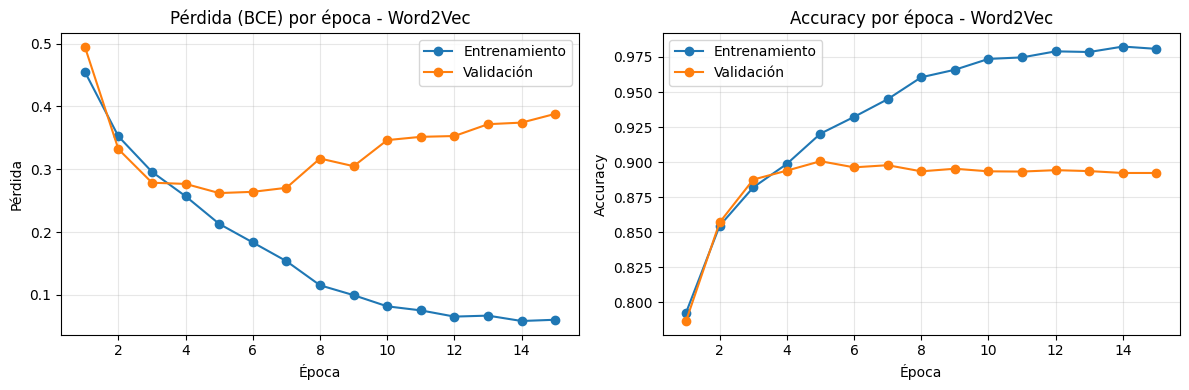

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
epocas_x = range(1, len(historial_w2v["train_loss"]) + 1)

axes[0].plot(epocas_x, historial_w2v["train_loss"], marker="o", label="Entrenamiento")
axes[0].plot(epocas_x, historial_w2v["val_loss"], marker="o", label="Validación")
axes[0].set_title("Pérdida (BCE) por época - Word2Vec")
axes[0].set_xlabel("Época"); axes[0].set_ylabel("Pérdida")

axes[1].plot(epocas_x, historial_w2v["train_acc"], marker="o", label="Entrenamiento")
axes[1].plot(epocas_x, historial_w2v["val_acc"], marker="o", label="Validación")
axes[1].set_title("Accuracy por época - Word2Vec")
axes[1].set_xlabel("Época"); axes[1].set_ylabel("Accuracy")

for ax in axes:
    ax.grid(alpha=0.3); ax.legend()
plt.tight_layout()
plt.show()

### 17. Evaluación en el conjunto de prueba (Word2Vec)

El mejor modelo Word2Vec se evalúa con el mismo conjunto de prueba (15 %) usado para GloVe.

Accuracy : 0.9059
Precisión: 0.8979
Recall   : 0.9163
F1-score : 0.9070
AUC      : 0.9633
Pérdida test: 0.2489 | mejor pérdida validación: 0.2621

              precision    recall  f1-score   support

    Negativa     0.9141    0.8954    0.9047      2973
    Positiva     0.8979    0.9163    0.9070      2986

    accuracy                         0.9059      5959
   macro avg     0.9060    0.9058    0.9058      5959
weighted avg     0.9060    0.9059    0.9058      5959



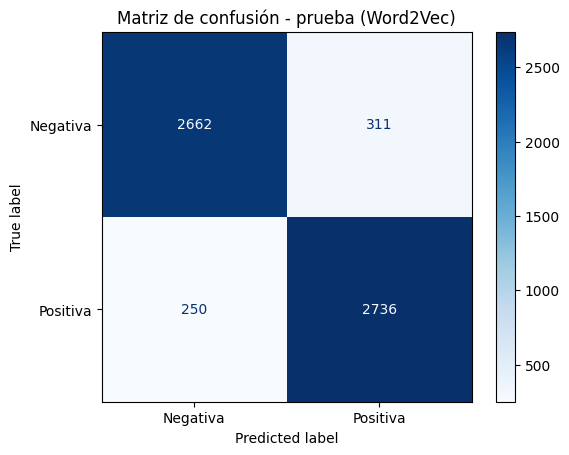

In [23]:
modelo_w2v.eval()
probs_w2v, reales_w2v = [], []
with torch.no_grad():
    for xb, yb in test_loader_w2v:
        probs_w2v.append(modelo_w2v(xb.to(device)).cpu())
        reales_w2v.append(yb)
probs_w2v = torch.cat(probs_w2v).numpy()
y_real_w2v = torch.cat(reales_w2v).numpy().astype(int)
y_pred_w2v = (probs_w2v >= 0.5).astype(int)

test_loss_w2v = criterio_w2v(torch.tensor(probs_w2v), torch.tensor(y_real_w2v, dtype=torch.float32)).item()
auc_w2v = roc_auc_score(y_real_w2v, probs_w2v)

print(f"Accuracy : {accuracy_score(y_real_w2v, y_pred_w2v):.4f}")
print(f"Precisión: {precision_score(y_real_w2v, y_pred_w2v):.4f}")
print(f"Recall   : {recall_score(y_real_w2v, y_pred_w2v):.4f}")
print(f"F1-score : {f1_score(y_real_w2v, y_pred_w2v):.4f}")
print(f"AUC      : {auc_w2v:.4f}")
print(f"Pérdida test: {test_loss_w2v:.4f} | mejor pérdida validación: {mejor_val_loss_w2v:.4f}\n")
print(classification_report(y_real_w2v, y_pred_w2v, target_names=["Negativa", "Positiva"], digits=4))

ConfusionMatrixDisplay(confusion_matrix(y_real_w2v, y_pred_w2v),
                       display_labels=["Negativa", "Positiva"]).plot(cmap="Blues", values_format="d")
plt.title("Matriz de confusión - prueba (Word2Vec)")
plt.show()

### 18. Comparación GloVe 300d vs. Word2Vec

Se comparan las métricas de prueba de los dos modelos y sus curvas ROC. En los dos casos la pérdida es entropía cruzada binaria, así que también se puede comparar. Hay que tener en cuenta que los modelos no solo cambian en el embedding: también cambian la arquitectura y el largo de las secuencias.

                                Accuracy  Precisión  Recall  F1-score     AUC  \
GloVe 300d (BiLSTM + atención)    0.8938     0.8838  0.9072    0.8954  0.9598   
Word2Vec 100d (LSTM 2 capas)      0.9059     0.8979  0.9163    0.9070  0.9633   

                                Pérdida test  Épocas  
GloVe 300d (BiLSTM + atención)        0.2632     8.0  
Word2Vec 100d (LSTM 2 capas)          0.2489    15.0  


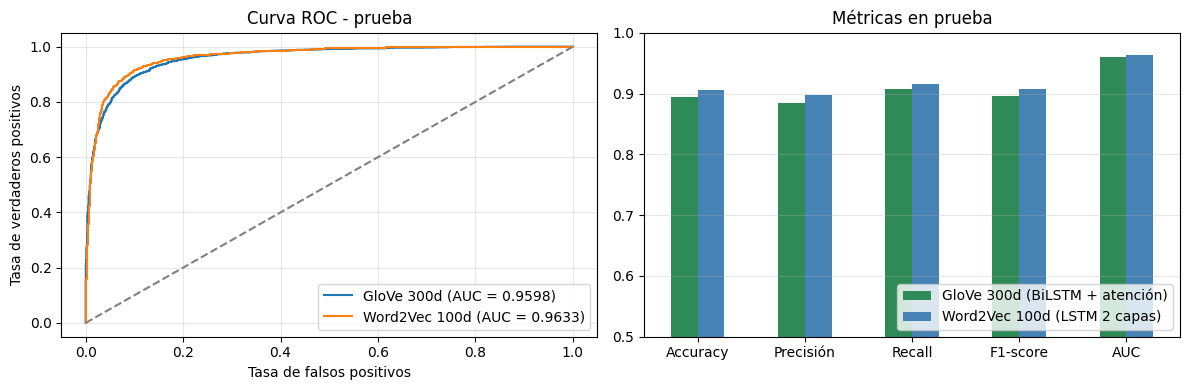

In [24]:
def metricas(y_true, y_hat, prob, perdida, historial_modelo):
    return {
        "Accuracy": accuracy_score(y_true, y_hat),
        "Precisión": precision_score(y_true, y_hat),
        "Recall": recall_score(y_true, y_hat),
        "F1-score": f1_score(y_true, y_hat),
        "AUC": roc_auc_score(y_true, prob),
        "Pérdida test": perdida,
        "Épocas": len(historial_modelo["train_loss"]),
    }

comparacion = pd.DataFrame({
    "GloVe 300d (BiLSTM + atención)": metricas(y_real, y_pred, probs, test_loss, historial),
    "Word2Vec 100d (LSTM 2 capas)": metricas(y_real_w2v, y_pred_w2v, probs_w2v, test_loss_w2v, historial_w2v),
}).T
print(comparacion.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for nombre, y_t, p in [("GloVe 300d", y_real, probs), ("Word2Vec 100d", y_real_w2v, probs_w2v)]:
    fpr, tpr, _ = roc_curve(y_t, p)
    axes[0].plot(fpr, tpr, label=f"{nombre} (AUC = {roc_auc_score(y_t, p):.4f})")
axes[0].plot([0, 1], [0, 1], "--", color="gray")
axes[0].set_title("Curva ROC - prueba")
axes[0].set_xlabel("Tasa de falsos positivos")
axes[0].set_ylabel("Tasa de verdaderos positivos")
axes[0].legend(); axes[0].grid(alpha=0.3)

cols = ["Accuracy", "Precisión", "Recall", "F1-score", "AUC"]
comparacion[cols].T.plot(kind="bar", ax=axes[1], rot=0, color=["seagreen", "steelblue"])
axes[1].set_ylim(0.5, 1.0)
axes[1].set_title("Métricas en prueba")
axes[1].grid(axis="y", alpha=0.3)
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()